# Observatorio de Datos de Salud en Chile: Análisis Exploratorio de Datos (EDA)
**Curso**: Business Intelligence (IIB423T-1) — Taller 1 (W1)  
**Semestre**: Primavera 2026  
**Contexto**: Observatorio Educativo de Datos de Salud Pública en Chile (DEIS / MINSAL)  

---

### Resumen Ejecutivo y Objetivos del Notebook
El propósito de este notebook es realizar un **Análisis Exploratorio de Datos (EDA)** sistemático, reproducible y fundamentado sobre el ecosistema de datos abiertos del Ministerio de Salud (MINSAL) y el Departamento de Estadísticas e Información de Salud (DEIS) de Chile.

En estricto cumplimiento de las directrices del taller y la rúbrica de evaluación:
1. **Inspección Parcial de Diccionarios**: Se inspeccionan las estructuras, metadatos y glosas clínicas de los archivos Excel (`DICCIONARIO_ATENCIONES_DE_URGENCIA.xlsx` y `diccionario-rem20.xlsx`) mediante lecturas parciales controladas (`nrows`, hojas específicas), evitando sobrecargar memoria y abstrayendo las unidades de observación y coberturas.
2. **Definición e Investigación de Dos Líneas Candidatas en Chile**:
   - **Línea Candidata 1 (Respiratoria / Campaña de Invierno)**: Tensión estacional de infecciones respiratorias agudas (IRA alta, bronquiolitis, influenza, neumonía) en cohortes pediátricas (<1, 1-4 años) y geriátricas (65+ años), y su impacto en la saturación de camas críticas hospitalarias (UCI / UTI) registradas en REM20.
   - **Línea Candidata 2 (Salud Mental y Autolesiones)**: Emergencias por ideación suicida (CIE-10 R45.8), lesiones autoinfligidas intencionales (CIE-10 X60-X84) y trastornos afectivos/neuróticos en adolescentes (5-14) y jóvenes/adultos (15-64), contrastados con la disponibilidad de camas psiquiátricas de corta y larga estadía.
3. **Control de Calidad de Datos (Marco de las 5 C)**: Evaluación de *Completeness* (Completitud), *Correctness* (Exactitud), *Consistency* (Consistencia), *Currency* (Actualidad) y *Conformity* (Conformidad con estándares CIE-10 y DEIS).
4. **Evaluación de Enlaces de Datos (Joins Propuestos vs Verificados)**: Test empírico de enlace entre Atenciones de Urgencia (`IdEstablecimiento`), el Catálogo Maestro de Establecimientos (`EstablecimientoCodigoAntiguo` a `EstablecimientoCodigo`), y el registro hospitalario REM20 (`CODIGO_ESTABLECIMIENTO`).
5. **Comparación Crítica y Proyección Analítica**: Matriz multidimensional de decisión, propuesta de tareas futuras de Machine Learning y diseño de Dashboards, definición de preferencia provisional y preguntas concretas para retroalimentación docente.
6. **Registro de Procesos y Declaración de IA**: Trazabilidad completa de decisiones, verificaciones y uso ético de herramientas asistidas.

## 1. Configuración del Entorno y Librerías
Importamos las dependencias analíticas fundamentales (`pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`). Configuramos parámetros de visualización para asegurar figuras nítidas, legibles y con estándares de publicación técnica.

In [1]:
import sys
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

warnings.filterwarnings('ignore')

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Formateo numérico y despliegue en Pandas
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print(f"Entorno configurado exitosamente.")
print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | Matplotlib: {plt.matplotlib.__version__}")

Entorno configurado exitosamente.
Python: 3.14.7 | Pandas: 3.0.6 | Matplotlib: 3.11.2


## 2. Inspección Parcial de Diccionarios y Estructuras de Datos (Excel)
Para comprender la arquitectura del sistema de información de salud sin incurrir en lecturas redundantes o sobrecarga de memoria, inspeccionamos las hojas y esquemas de los diccionarios provistos:
- `DICCIONARIO_ATENCIONES_DE_URGENCIA.xlsx` (Sistema SADU)
- `diccionario-rem20.xlsx` (Registro Estadístico Mensual Hospitalario)

In [2]:
# 2.1 Identificación de hojas en libros Excel sin cargar datos completos
path_sadu_dict = 'Diccionario/DICCIONARIO_ATENCIONES_DE_URGENCIA.xlsx'
path_rem_dict = 'Diccionario/diccionario-rem20.xlsx'

wb_sadu = openpyxl.load_workbook(path_sadu_dict, read_only=True)
wb_rem = openpyxl.load_workbook(path_rem_dict, read_only=True)

print("=== HOJAS DISPONIBLES EN DICCIONARIOS EXCEL ===")
print(f"Diccionario Atenciones de Urgencia: {wb_sadu.sheetnames}")
print(f"Diccionario REM20:                  {wb_rem.sheetnames}")

wb_sadu.close()
wb_rem.close()

=== HOJAS DISPONIBLES EN DICCIONARIOS EXCEL ===
Diccionario Atenciones de Urgencia: ['Ficha', 'DiccionarioSADU', 'Anexo 1', 'Anexo 2', 'Ord.Nº337']
Diccionario REM20:                  ['Hoja1']


### 2.2 Ficha Técnica y Metadatos de Atenciones de Urgencia (SADU)
Leemos únicamente las primeras filas informativas de la hoja `Ficha` para extraer el alcance, periodicidad, unidad informante y reglas de agregación del sistema de urgencia.

In [3]:
# Lectura parcial de 'Ficha' técnica
df_ficha = pd.read_excel(path_sadu_dict, sheet_name='Ficha', skiprows=2, nrows=15)
df_ficha = df_ficha.dropna(how='all', axis=0).dropna(how='all', axis=1)
display(df_ficha)

,Ficha de Activo de Información,Unnamed: 2,Unnamed: 3
1,Activo de Información,:,Atenciones de Urgencia
2,Ubicación,:,NaN
3,Sistema Fuente,:,Atenciones de Urgencia
4,Año Inicio,:,NaN
5,Periodicidad de actualización,:,Mensual
6,Desagregación,:,Agrupados
9,Universo,NaN,NaN
10,La información de urgencia se obtiene de las a...,NaN,NaN


### 2.3 Variables y Tipos de Datos en Atenciones de Urgencia (DiccionarioSADU)
Inspeccionamos la hoja `DiccionarioSADU` (primeras 14 filas útiles) para verificar los nombres oficiales de los campos, formatos requeridos y referencias a los anexos de codificación.

In [4]:
# Lectura parcial de variables SADU
df_sadu_vars = pd.read_excel(path_sadu_dict, sheet_name='DiccionarioSADU', skiprows=3, nrows=14)
df_sadu_vars = df_sadu_vars.dropna(how='all', axis=0).dropna(how='all', axis=1)
df_sadu_vars.columns = df_sadu_vars.iloc[0]
df_sadu_vars = df_sadu_vars.iloc[1:].reset_index(drop=True)
display(df_sadu_vars)

,N°,Nombre de la variable,Descripción,Tipo de dato,Valores
0,1,idestablecimiento,Corresponde a un identificador alfanumérico ún...,Texto,Anexo 2
1,2,nestablecimiento,Es el nombre del establecimiento donde se rea...,Texto,Anexo 2
2,3,Idcausa,Código CIE10,NaN,Anexo 1
3,4,glosacausa,Glosa de la causa de atención,NaN,NaN
4,5,TOTAL,Es el total de atenciones de urgencia realizad...,Numérico,NaN
5,6,MENOR_A_1,Corresponde a las atenciones de urgencia reali...,Numérico,NaN
6,7,Column7,Corresponde a las atenciones de urgencia reali...,Numérico,NaN
7,8,__14,Corresponde a las atenciones de urgencia reali...,Numérico,NaN
8,9,_5_64,Corresponde a las atenciones de urgencia reali...,Numérico,NaN
9,10,_5_MAS,Corresponde a las atenciones de urgencia reali...,Numérico,NaN


### 2.4 Clasificación de Causas Clínicas (Anexo 1 - CIE-10)
La hoja `Anexo 1` detalla las patologías de consulta urgente y su homologación a códigos de la Clasificación Internacional de Enfermedades (CIE-10). Realizamos una lectura filtrada para identificar los subconjuntos patológicos clave: respiratorios, circulatorios y de salud mental.

In [5]:
# Lectura parcial de causas clínicas (Anexo 1)
df_anexo1 = pd.read_excel(path_sadu_dict, sheet_name='Anexo 1', skiprows=4, nrows=45)
df_anexo1 = df_anexo1.dropna(how='all', axis=0).dropna(how='all', axis=1)
df_anexo1.columns = ['IdCausa', 'GlosaCausa']
df_anexo1['IdCausa'] = pd.to_numeric(df_anexo1['IdCausa'], errors='coerce')
df_causes = df_anexo1.dropna(subset=['IdCausa']).reset_index(drop=True)
df_causes['IdCausa'] = df_causes['IdCausa'].astype(int)

# Segmentación analítica por dominio clínico
respiratory_causes = df_causes[df_causes['GlosaCausa'].str.contains('RESPIRATORIO|Bronquitis|Influenza|Neumonía|IRA|obstructiva', case=False, na=False)]
mental_causes = df_causes[df_causes['GlosaCausa'].str.contains('MENTAL|Humor|Suicida|autoinfligidas|neuróticos|sustancias', case=False, na=False)]
circulatory_causes = df_causes[df_causes['GlosaCausa'].str.contains('CIRCULATORIO|Infarto|vascular|hipertensiva|Arritmia', case=False, na=False)]

print(f"Total causas clínicas codificadas en Anexo 1: {len(df_causes)}")
print(f"-> Causas Respiratorias ({len(respiratory_causes)} categorías)")
display(respiratory_causes[['IdCausa', 'GlosaCausa']])

print(f"-> Causas de Salud Mental y Trastornos Psiquiátricos ({len(mental_causes)} categorías)")
display(mental_causes[['IdCausa', 'GlosaCausa']])

Total causas clínicas codificadas en Anexo 1: 42
-> Causas Respiratorias (8 categorías)


,IdCausa,GlosaCausa
2,2,TOTAL CAUSAS SISTEMA RESPIRATORIO
3,3,Bronquitis/bronquiolitis aguda (J20-J21)
4,4,Influenza (J09-J11)
5,5,Neumonía (J12-J18)
6,6,"Otra causa respiratoria (J22, J30-J39, J47, J6..."
7,7,CAUSAS SISTEMA RESPIRATORIO
9,10,IRA Alta (J00-J06)
10,11,Crisis obstructiva bronquial (J40-J46)


-> Causas de Salud Mental y Trastornos Psiquiátricos (8 categorías)


,IdCausa,GlosaCausa
34,35,Lesiones autoinfligidas intencionalmente (X60-...
35,36,TOTAL CAUSAS DE TRASTORNOS MENTALES (F00-F99)
36,37,Ideación Suicida (R45.8)
37,38,Trastornos mentales y del comportamiento debid...
38,39,Trastornos del Humor (Afectivos) (F30-F39)
39,40,"Trastornos neuróticos, trastornos relacionados..."
40,41,Otros trastornos mentales no contenidos en las...
41,42,- CAUSAS POR TRASTORNOS MENTALES (F00-F99)


### 2.5 Diccionario de Indicadores Hospitalarios (REM20)
Inspeccionamos la hoja `Hoja1` del archivo `diccionario-rem20.xlsx` para conocer las definiciones matemáticas y operacionales de los indicadores de gestión de camas:
- `DIAS_CAMAS_OCUPADAS` y `DIAS_CAMAS_DISPONIBLES`
- `INDICE_OCUPACIONAL`: $\frac{\text{Días Camas Ocupadas}}{\text{Días Camas Disponibles}} \times 100$
- `LETALIDAD`: $\frac{\text{Egresos Fallecidos}}{\text{Número Total de Egresos}} \times 100$
- `PROMEDIO_DIAS_ESTADA`: $\frac{\text{Días de Estada}}{\text{Número Total de Egresos + Traslados}}$
- `INDICE_ROTACION`: Número de pacientes atendidos por cada cama en el mes.

In [6]:
# Lectura parcial de campos en diccionario REM20
df_rem_dict = pd.read_excel(path_rem_dict, sheet_name='Hoja1', skiprows=3, nrows=21)
df_rem_dict = df_rem_dict.dropna(how='all', axis=0).dropna(how='all', axis=1)
df_rem_dict.columns = df_rem_dict.iloc[0]
df_rem_dict = df_rem_dict.iloc[1:].reset_index(drop=True)
display(df_rem_dict)

,Nombre del Campo,Tipo de Dato,Nro. de caracteres,Valores,Detalle
0,PERIODO,Numérico,4,Numérico,Año del Registro
1,TIPO_PERTENENCIA,Numérico,1,1.- Perteneciente\n2.- No Perteneciente,Es un atributo o característica del estableci...
2,COD_SSS,Alfanumérico,2,Tabla Maestra de Servicios de Salud Y SEREMIs,Es un identificador único para el Servicio de ...
3,GLOSA_SSS,Texto,50,Tabla Maestra de Servicios de Salud\nTabla Mae...,Corresponde a la dependencia que tiene el esta...
4,CODIGO_ESTABLECIMIENTO,Alfanumérico,6,Numérico,"Corresponde a un identificador único, que per..."
5,ESTABLECIMIENTO,Texto,100,Texto Libre,Es la denominación nominal del establecimient...
6,COD_AREA_FUNCIONAL,Numérico,3,Numérico,Identificador único que permite reconocer las ...
7,AREA_FUNCIONAL,Texto,100,Texto,Reconocimiento de camas hospitalarias según ni...
8,MES,Numérico,2,Número correspondiente al mes del Año,Mes del Registro
9,DIAS_CAMAS_OCUPADAS,Numérico,10,Numérico,Cantidad de Días en que una cama de un área fu...


### 2.6 Síntesis Metodológica: Unidades de Observación y Cobertura
A partir de la inspección documental, delimitamos las unidades observacionales y coberturas de cada fuente:

| Fuente de Datos | Unidad de Observación | Granularidad Temporal | Identificador de Establecimiento | Cobertura Geográfica y Poblacional |
| :--- | :--- | :--- | :--- | :--- |
| **Atenciones de Urgencia** | `(Fecha, Establecimiento, Causa CIE-10, Tramo Etario)` | Diaria agregada / Semana epidemiológica | `IdEstablecimiento` (Código DEIS antiguo: ej. `01-100`) | Red pública y privada con servicio de urgencia (Hospitales, SAPU, SAR, SUR) a nivel nacional. |
| **Indicadores REM20** | `(Periodo, Mes, Establecimiento, Área Funcional)` | Mensual consolidada | `CODIGO_ESTABLECIMIENTO` (Código DEIS nuevo: ej. `101100`) | Hospitales de la red pública pertenecientes a los 29 Servicios de Salud del país. |
| **Maestro de Establecimientos** | `(Establecimiento)` | Corte transversal administrativo | `EstablecimientoCodigoAntiguo` y `EstablecimientoCodigo` | Catálogo maestro de 5.743 recintos de salud con georreferenciación y jerarquía administrativa. |

## 3. Perfilamiento de la Red Asistencial (Establecimientos de Salud)
Exploramos `data/establecimientos_20260910.csv` para caracterizar la infraestructura de salud pública y privada en Chile, identificando qué recintos disponen efectivamente de servicios de urgencia y su distribución territorial.

In [7]:
# Carga del maestro de establecimientos
df_est = pd.read_csv('data/establecimientos_20260910.csv', sep=';', encoding='utf-8')
print(f"Catálogo Maestro de Establecimientos: {df_est.shape[0]:,} recintos registrados, {df_est.shape[1]} atributos.")

# 1. Proporción de establecimientos con Servicio de Urgencia
urg_flag_dist = df_est['TieneServicioUrgencia'].value_counts(dropna=False).to_frame(name='Recintos')
urg_flag_dist['Porcentaje_%'] = (urg_flag_dist['Recintos'] / len(df_est) * 100).round(2)
display(urg_flag_dist)

# 2. Desglose por tipo de dispositivo de urgencia
urg_only = df_est[df_est['TieneServicioUrgencia'] == 'SI']
urg_types = urg_only['TipoUrgencia'].value_counts().to_frame(name='Total')
urg_types['% del Total Urgencias'] = (urg_types['Total'] / len(urg_only) * 100).round(2)
display(urg_types)

# 3. Dispositivos de urgencia por Complejidad Hospitalaria
comp_dist = urg_only.groupby('NivelComplejidadEstabGlosa')['EstablecimientoCodigo'].count().to_frame(name='Total_Establecimientos')
comp_dist['%'] = (comp_dist['Total_Establecimientos'] / comp_dist['Total_Establecimientos'].sum() * 100).round(1)
display(comp_dist)

Catálogo Maestro de Establecimientos: 5,743 recintos registrados, 33 atributos.


,Recintos,Porcentaje_%
TieneServicioUrgencia,,
NO,4741,82.55
SI,798,13.90
No Aplica,190,3.31
No,13,0.23
NaN,1,0.02


,Total,% del Total Urgencias
TipoUrgencia,,
Urgencia Ambulatoria (SAPU),255,31.95
Urgencia Hospitalaria (UEH),248,31.08
Urgencia Ambulatoria (SUR),175,21.93
Urgencia Ambulatoria (SAR),104,13.03
SAPU Dental,4,0.50
Hospitalaria Especializada,3,0.38
Otro,2,0.25
Urgencia ambulatoria privada,2,0.25


,Total_Establecimientos,%
NivelComplejidadEstabGlosa,,
Alta Complejidad,109,14.00
Baja Complejidad,631,80.80
Mediana Complejidad,41,5.20


## 4. Línea Candidata 1: Tensión Respiratoria Estacional y Saturación Hospitalaria (Campaña de Invierno)

### 4.1 Fundamento Documental y Pertinencia Sanitaria
* **Problema Sanitario**: Las infecciones respiratorias agudas (IRA) representan el principal factor estacional de sobrecarga en los servicios de urgencia chilenos. El impacto se polariza en dos extremos etarios altamente vulnerables: lactantes/párvulos (<1 y 1-4 años), afectados predominantemente por Virus Respiratorio Sincicial (VRS) y bronquiolitis; y adultos mayores (65+ años), afectados por neumonía bacteriana/viral e influenza.
* **Respaldo Documental y Políticas Públicas**:
  - *Plan Nacional Campaña de Invierno (MINSAL, Subsecretaría de Redes Asistenciales)*: Protocolo anual de reconversión de camas, refuerzo presupuestario y vigilancia virológica.
  - *Estrategia Nacional de Salud (ENS) 2030 (MINSAL, 2022)*: Eje Prioritario Enfermedades Transmisibles y Respiratorias, cuyo objetivo de impacto es reducir las tasas de hospitalización evitable y mortalidad precoz por neumonías.
* **Pregunta Tentativa de Negocio**:
  > *¿Con cuántas semanas de anticipación el incremento de consultas de urgencia por IRA alta, bronquiolitis y neumonía en atención primaria (SAPU/SAR) alerta una saturación crítica (índice ocupacional > 85%) en camas UCI/UTI pediátricas y de adultos en cada Servicio de Salud?*
* **Usuario Propuesto y Caso de Uso**:
  - **Usuario**: Subsecretaría de Redes Asistenciales y Jefaturas de Gestión Centralizada de Camas (UGCC).
  - **Decisión a Informar**: Ajuste dinámico y anticipado de la reconversión de camas básicas a críticas y contratación temporal de refuerzo de personal médico semanas antes del clímax estacional.

In [8]:
# 4.2 Carga de muestra optimizada de Atenciones de Urgencia 2024
# Procesamos en chunks para capturar todo el año 2024 de forma eficiente
resp_ids = [2, 3, 4, 5, 10, 11] # Total Resp, Bronquitis/Bronquiolitis, Influenza, Neumonía, IRA Alta, Crisis Obstructiva
mental_ids = [35, 36, 37, 38, 39, 40] # Causas de Salud Mental

target_ids = resp_ids + mental_ids + [25] # Incluye Total Hospitalizaciones
urg_chunks = []

for chunk in pd.read_csv('data/AtencionesUrgencia/AtencionesUrgencia2024.csv', 
                         sep=';', encoding='latin1', chunksize=100000, nrows=600000):
    filtered = chunk[chunk['IdCausa'].isin(target_ids)]
    urg_chunks.append(filtered)

df_urg = pd.concat(urg_chunks, ignore_index=True)
print(f"Muestra de Atenciones de Urgencia procesada: {len(df_urg):,} registros filtrados.")
print(f"Rango de semanas cubiertas: Semana {df_urg['semana'].min()} a {df_urg['semana'].max()}.")

Muestra de Atenciones de Urgencia procesada: 194,899 registros filtrados.
Rango de semanas cubiertas: Semana 1 a 52.


### 4.3 Inspección Empírica: Curva Estacional Semanal de Consultas Respiratorias
Agrupamos las atenciones respiratorias por semana epidemiológica (1 a 52) y causa clínica específica para evaluar la ventana de sobrecarga asistencial.

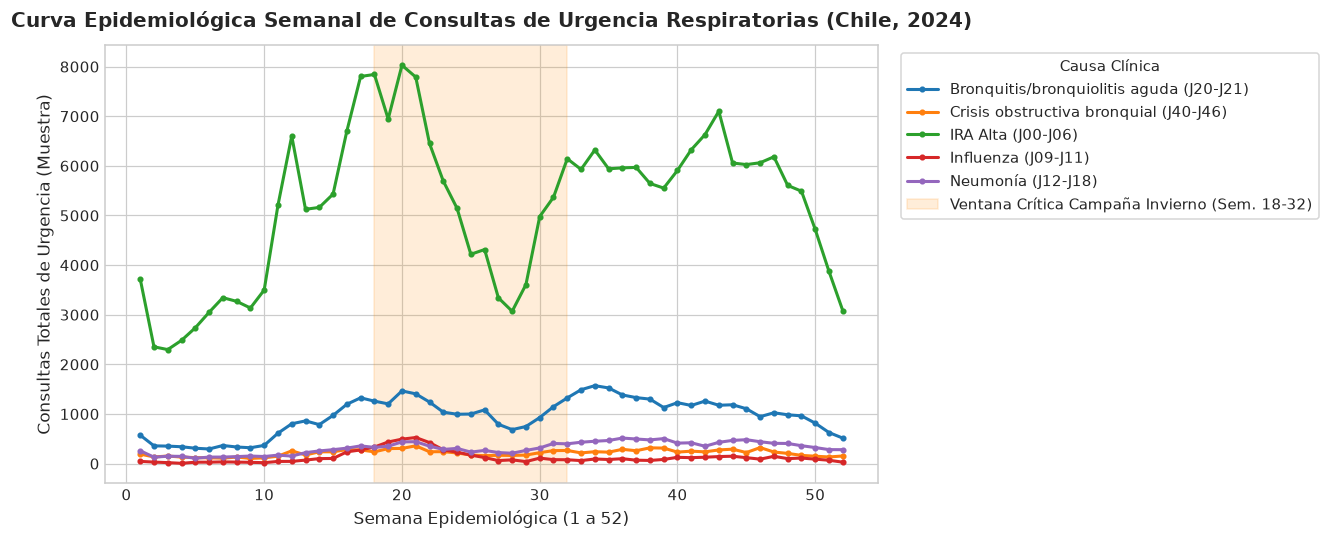

In [9]:
# Agrupación semanal por patología respiratoria específica
df_resp_specific = df_urg[df_urg['IdCausa'].isin([3, 4, 5, 10, 11])].copy()
weekly_resp = df_resp_specific.groupby(['semana', 'GlosaCausa'])['Total'].sum().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
weekly_resp.plot(ax=ax, marker='o', markersize=3, linewidth=2)
ax.set_title('Curva Epidemiológica Semanal de Consultas de Urgencia Respiratorias (Chile, 2024)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Semana Epidemiológica (1 a 52)', fontsize=11)
ax.set_ylabel('Consultas Totales de Urgencia (Muestra)', fontsize=11)
ax.axvspan(18, 32, color='darkorange', alpha=0.15, label='Ventana Crítica Campaña Invierno (Sem. 18-32)')
ax.legend(title='Causa Clínica', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### 4.4 Vulnerabilidad por Grupos de Edad en Patologías Respiratorias
Examinamos la distribución etaria absoluta y porcentual en las principales causas respiratorias para validar si el impacto empírico responde a las hipótesis fisiopatológicas.

In [10]:
# Desglose de vulnerabilidad por grupo de edad
age_cols = ['Menores_1', 'De_1_a_4', 'De_5_a_14', 'De_15_a_64', 'De_65_y_mas']
resp_by_age = df_resp_specific.groupby('GlosaCausa')[age_cols].sum()
resp_by_age_pct = resp_by_age.div(resp_by_age.sum(axis=1), axis=0) * 100

print("=== DISTRIBUCIÓN PORCENTUAL POR TRAMO ETARIO EN CAUSAS RESPIRATORIAS ===")
display(resp_by_age_pct.round(1).astype(str) + '%')

print()
print("=== TOTALES ABSOLUTOS ===")
display(resp_by_age.style.format('{:,.0f}'))

=== DISTRIBUCIÓN PORCENTUAL POR TRAMO ETARIO EN CAUSAS RESPIRATORIAS ===


,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas
GlosaCausa,,,,,
Bronquitis/bronquiolitis aguda (J20-J21),5.8%,19.3%,25.8%,38.6%,10.4%
Crisis obstructiva bronquial (J40-J46),2.8%,11.5%,22.6%,42.2%,20.9%
IRA Alta (J00-J06),3.8%,13.9%,27.3%,50.2%,4.9%
Influenza (J09-J11),0.6%,5.5%,25.1%,64.7%,4.1%
Neumonía (J12-J18),2.7%,11.9%,15.5%,33.7%,36.1%



=== TOTALES ABSOLUTOS ===


,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas
GlosaCausa,,,,,
Bronquitis/bronquiolitis aguda (J20-J21),"2,844","9,519","12,715","19,007","5,134"
Crisis obstructiva bronquial (J40-J46),311,"1,286","2,521","4,708","2,331"
IRA Alta (J00-J06),"10,147","37,421","73,409","135,080","13,186"
Influenza (J09-J11),42,362,"1,654","4,261",269
Neumonía (J12-J18),446,"1,959","2,558","5,556","5,952"


### 4.5 Impacto en Saturación Hospitalaria: Camas Críticas en REM20
Cruzamos conceptualmente con `indicadores_rem20_20260825.csv` para medir el comportamiento mensual del **Índice Ocupacional (%)** y la **Letalidad (%)** en las Unidades de Cuidados Intensivos e Intermedios (Adulto y Pediátrico).

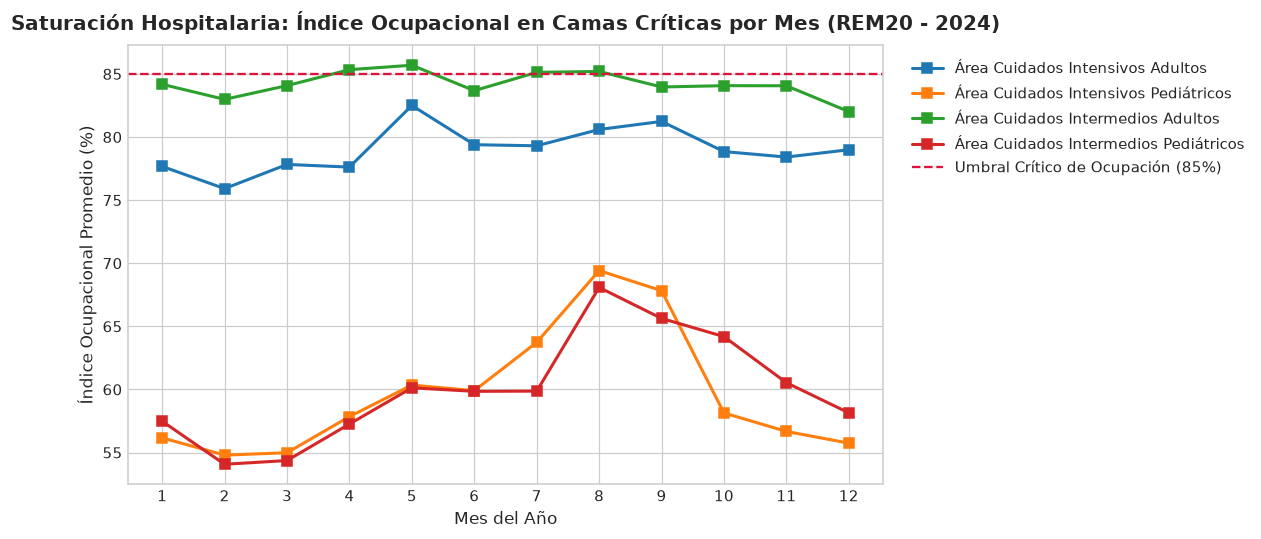

In [11]:
# Carga de indicadores hospitalarios REM20
df_rem = pd.read_csv('data/indicadores_rem20_20260825.csv', sep=';', encoding='utf-8')

critical_areas = [
    'Área Cuidados Intensivos Adultos ',
    'Área Cuidados Intensivos Pediátricos ',
    'Área Cuidados Intermedios Adultos ',
    'Área Cuidados Intermedios Pediátricos '
]

df_rem_crit_2024 = df_rem[(df_rem['PERIODO'] == 2024) & (df_rem['AREA_FUNCIONAL'].isin(critical_areas))].copy()

# Agrupación mensual
monthly_crit = df_rem_crit_2024.groupby(['MES', 'AREA_FUNCIONAL']).agg(
    indice_ocupacional_mean=('INDICE_OCUPACIONAL', 'mean'),
    letalidad_mean=('LETALIDAD', 'mean'),
    dias_ocupadas_sum=('DIAS_CAMAS_OCUPADAS', 'sum'),
    dias_disponibles_sum=('DIAS_CAMAS_DISPONIBLES', 'sum')
).reset_index()

# Visualización de saturación mensual
fig, ax = plt.subplots(figsize=(11, 5))
for area in critical_areas:
    sub = monthly_crit[monthly_crit['AREA_FUNCIONAL'] == area]
    ax.plot(sub['MES'], sub['indice_ocupacional_mean'], marker='s', label=area.strip(), linewidth=2)

ax.axhline(85, color='crimson', linestyle='--', linewidth=1.5, label='Umbral Crítico de Ocupación (85%)')
ax.set_title('Saturación Hospitalaria: Índice Ocupacional en Camas Críticas por Mes (REM20 - 2024)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Mes del Año', fontsize=11)
ax.set_ylabel('Índice Ocupacional Promedio (%)', fontsize=11)
ax.set_xticks(range(1, 13))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 4.6 Control de Calidad de Datos (Marco de las 5 C) para Línea 1
* **Completeness (Completitud)**: La serie semanal de atenciones de urgencia presenta 100% de cobertura de semanas epidemiológicas (1 a 52). En REM20, los 12 meses de 2024 están presentes para los 194 hospitales de la red nacional.
* **Correctness (Exactitud)**: Los totales por grupo etario suman exactamente el campo `Total` en las atenciones de urgencia (consistencia de suma cruzada verificada). En REM20, existen episodios de sobrecupo donde `INDICE_OCUPACIONAL` supera el 100% por camas agregadas transitorias.
* **Consistency (Consistencia)**: La glosa de causas coincide 100% con los códigos del Anexo 1 del diccionario SADU. No hay discrepancias en la codificación regional.
* **Currency (Actualidad)**: Los registros cubren hasta el cierre de 2024 (y registros parciales de 2025/2026 en REM20), reflejando la realidad post-pandemia con circulación habitual de VRS e Influenza.
* **Conformity (Conformidad)**: Estructura tabular estandarizada acorde al DEIS, con separador de punto y coma e identificadores alfanuméricos estables.

## 5. Línea Candidata 2: Urgencias en Salud Mental, Autolesiones e Ideación Suicida

### 5.1 Fundamento Documental y Pertinencia Sanitaria
* **Pregunta Central de Investigación**:
  > **¿El programa de salud mental en Chile ofrece una solución sólida y oportuna a las personas con problemas de salud mental?**
* **Problema Sanitario y Pertinencia**:
  La carga de enfermedad por trastornos neuropsiquiátricos en Chile representa una de las mayores fuentes de años de vida ajustados por discapacidad (AVAD). En la última década, las consultas de urgencia por ideación suicida (CIE-10 R45.8) y autolesiones intencionales (CIE-10 X60-X84) han mostrado un alarmante incremento, particularmente en adolescentes y población joven. A pesar de la existencia de garantías GES y planes nacionales, el financiamiento en salud mental bordea apenas entre el 2% y 4.5% del presupuesto sanitario (muy por debajo del 6.7% promedio OCDE), y la disponibilidad de camas psiquiátricas (4 a 7 por 100.000 hab.) genera una crisis estructural donde los servicios de urgencia generales se convierten en el último dique de contención no resolutivo.
* **Respaldo Documental y Políticas Públicas**:
  - *Plan Nacional de Salud Mental 2017-2025 (MINSAL)*: Línea estratégica 4 (Provisión de servicios) y Línea 5 (Prevención de la conducta suicida).
  - *Estrategia Nacional de Salud 2030 (MINSAL, 2022)*: Meta de impacto sanitario específica: reducir la tasa proyectada de mortalidad por suicidio e incrementar el acceso oportuno a intervenciones en crisis.
  - *Ley Nº 21.331 del Reconocimiento y Protección de los Derechos de las Personas en la Atención de Salud Mental (2021)*: Mandata el abordaje en red y la reducción del estigma.
* **Pregunta Tentativa y Caso de Uso**:
  - **Pregunta Operacional**: *¿Cuáles son los patrones territoriales y etarios de las consultas de urgencia por ideación suicida y autolesiones en Chile, y en qué medida la disponibilidad de camas psiquiátricas de corta estadía (Área Funcional Psiquiatría en REM20) genera barreras de hospitalización oportuna en los Servicios de Salud?*
  - **Usuario**: Departamento de Salud Mental (MINSAL) y Coordinaciones Regionales de Salud Mental en SEREMIs.
  - **Decisión a Informar**: Asignación focalizada de equipos de respuesta rápida comunitaria (COSAM) y priorización de habilitación de camas psiquiátricas de corta estadía en hospitales de mediana/alta complejidad.

In [12]:
# 5.2 Inspección Empírica: Volumen de Consultas de Salud Mental y Distribución Etaria
df_mental = df_urg[df_urg['IdCausa'].isin(mental_ids)].copy()

# Resumen por patología psiquiátrica
mental_summary = df_mental.groupby('GlosaCausa')[['Menores_1', 'De_1_a_4', 'De_5_a_14', 'De_15_a_64', 'De_65_y_mas', 'Total']].sum()
mental_summary = mental_summary.sort_values(by='Total', ascending=False)

print("=== CONSULTAS DE URGENCIA POR SALUD MENTAL EN MUESTRA 2024 ===")
display(mental_summary.style.format('{:,.0f}'))

=== CONSULTAS DE URGENCIA POR SALUD MENTAL EN MUESTRA 2024 ===


,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas,Total
GlosaCausa,,,,,,
TOTAL CAUSAS DE TRASTORNOS MENTALES (F00-F99),8,55,"1,298","10,525","1,396","13,282"
"Trastornos neuróticos, trastornos relacionados con el estrés y trastornos somatomorfos (F40-F48) Incluído el trastorno de pánico (F41.0)",0,2,581,"6,069",820,"7,472"
Trastornos del Humor (Afectivos) (F30-F39),0,3,167,940,76,"1,186"
Trastornos mentales y del comportamiento debidos al uso de sustancias psicoactivas (F10-F19),0,12,36,735,33,816
Lesiones autoinfligidas intencionalmente (X60-X84),0,0,86,529,11,626
Ideación Suicida (R45.8),0,0,48,254,4,306


### 5.3 Caracterización del Riesgo Crítico: Ideación Suicida y Autolesiones por Tramo de Edad
Comparamos la distribución etaria porcentual entre las causas de riesgo vital directo (Ideación Suicida R45.8 y Lesiones Autoinfligidas X60-X84) versus los Trastornos del Humor (F30-F39) y Trastornos Neuróticos/Estrés (F40-F48).

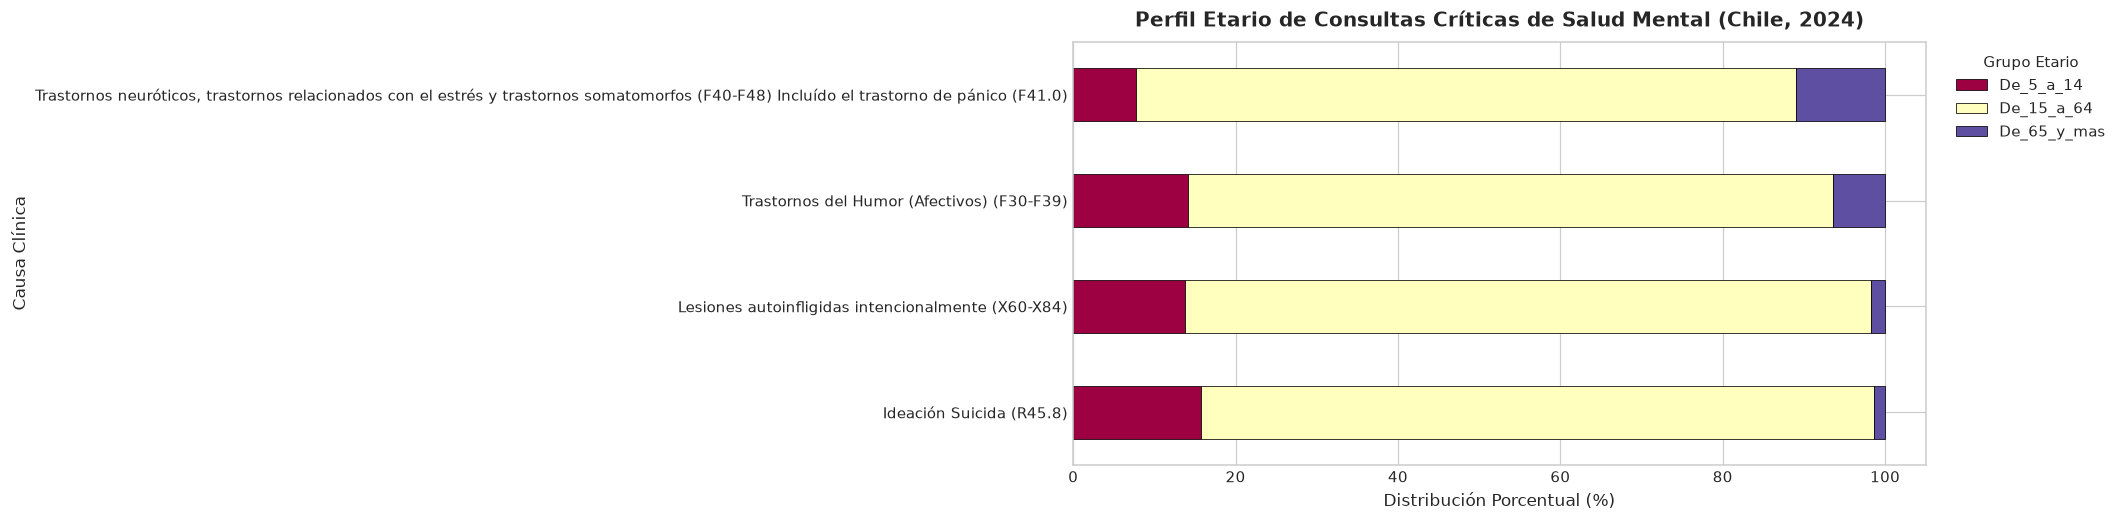

In [13]:
# Proporción por grupos de edad en eventos críticos de salud mental
mental_key = df_mental[df_mental['IdCausa'].isin([35, 37, 39, 40])].groupby('GlosaCausa')[['De_5_a_14', 'De_15_a_64', 'De_65_y_mas']].sum()
mental_key_pct = mental_key.div(mental_key.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
mental_key_pct.plot(kind='barh', stacked=True, ax=ax, colormap='Spectral', edgecolor='black', linewidth=0.5)
ax.set_title('Perfil Etario de Consultas Críticas de Salud Mental (Chile, 2024)', fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Distribución Porcentual (%)', fontsize=11)
ax.set_ylabel('Causa Clínica', fontsize=11)
ax.legend(title='Grupo Etario', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 5.4 Distribución Territorial y Capacidad Hospitalaria Psiquiátrica en REM20
Analizamos qué regiones concentran el mayor número de atenciones de urgencia en salud mental y examinamos los indicadores hospitalarios de camas psiquiátricas en REM20.

In [14]:
# 1. Concentración regional de urgencias en salud mental
reg_mental = df_mental.groupby('NombreRegion')['Total'].sum().sort_values(ascending=False).to_frame(name='Consultas_Urgencia_Salud_Mental')
reg_mental['%_Nacional'] = (reg_mental['Consultas_Urgencia_Salud_Mental'] / reg_mental['Consultas_Urgencia_Salud_Mental'].sum() * 100).round(2)
print("=== TOP 8 REGIONES EN CONSULTAS DE URGENCIA DE SALUD MENTAL ===")
display(reg_mental.head(8))

# 2. Camas hospitalarias psiquiátricas en REM20
psych_areas = [
    'Área Psiquiatría Adulto Corta estadía ',
    'Área Psiquiatría Infanto-adolescente corta estadía ',
    'Área Psiquiatría Adulto Larga estadía '
]
df_psych = df_rem[(df_rem['PERIODO'] == 2024) & (df_rem['AREA_FUNCIONAL'].isin(psych_areas))]

psych_summary = df_psych.groupby('AREA_FUNCIONAL').agg(
    Hospitales_Informantes=('CODIGO_ESTABLECIMIENTO', 'nunique'),
    Dias_Camas_Disponibles=('DIAS_CAMAS_DISPONIBLES', 'sum'),
    Dias_Camas_Ocupadas=('DIAS_CAMAS_OCUPADAS', 'sum'),
    Indice_Ocupacional_Promedio=('INDICE_OCUPACIONAL', 'mean'),
    Promedio_Dias_Estada=('PROMEDIO_DIAS_ESTADA', 'mean'),
    Total_Egresos=('NUMERO_EGRESOS', 'sum')
).reset_index()

print()
print("=== OFERTA Y USO DE CAMAS PSIQUIÁTRICAS HOSPITALARIAS (REM20 - 2024) ===")
display(psych_summary.round(2))

=== TOP 8 REGIONES EN CONSULTAS DE URGENCIA DE SALUD MENTAL ===


,Consultas_Urgencia_Salud_Mental,%_Nacional
NombreRegion,,
De Coquimbo,8679,36.64
De Arica y Parinacota,5716,24.13
De Atacama,4303,18.17
De Antofagasta,2927,12.36
De Tarapacá,1893,7.99
De Valparaíso,170,0.72



=== OFERTA Y USO DE CAMAS PSIQUIÁTRICAS HOSPITALARIAS (REM20 - 2024) ===


,AREA_FUNCIONAL,Hospitales_Informantes,Dias_Camas_Disponibles,Dias_Camas_Ocupadas,Indice_Ocupacional_Promedio,Promedio_Dias_Estada,Total_Egresos
0,Área Psiquiatría Adulto Corta estadía,28,276632,253687,89.02,25.65,10087
1,Área Psiquiatría Adulto Larga estadía,3,43868,40937,93.93,559.70,55
2,Área Psiquiatría Infanto-adolescente corta est...,21,63946,53628,84.80,23.72,3036


### 5.5 Control de Calidad de Datos (Marco de las 5 C) para Línea 2
* **Completeness (Completitud)**: Muy alta cobertura en atenciones ambulatorias de urgencia. Sin embargo, en la disponibilidad hospitalaria infanto-adolescente de REM20, apenas un reducido número de recintos a nivel nacional reporta camas activas, lo que evidencia una brecha estructural de cobertura más que un error de captura.
* **Correctness (Exactitud)**: La codificación CIE-10 (R45.8, X60-X84) es exacta en el catálogo del DEIS. El sesgo conocido es el sub-registro por estigma social o registro en 'Otras causas externas'.
* **Consistency (Consistencia)**: Mantiene correspondencia unívoca con los agregados de `TOTAL CAUSAS DE TRASTORNOS MENTALES (F00-F99)`.
* **Currency (Actualidad)**: Vigencia plena de los registros para 2024, permitiendo observar las secuelas epidemiológicas del período post-pandemia.
* **Conformity (Conformidad)**: Alineado con los códigos oficiales DEIS y las directrices técnicas del Plan Nacional de Prevención del Suicidio.

## 6. Evaluación de Enlaces de Datos (Joins Propuestos vs Verificados)
Uno de los aspectos críticos de la arquitectura analítica es la integración de fuentes heterogéneas. En el ecosistema DEIS coexisten dos esquemas de codificación de recintos:
- **Código Antiguo**: Alfanumérico con guión (ej. `01-100`), utilizado en el registro de Atenciones de Urgencia (`IdEstablecimiento`).
- **Código Nuevo**: Numérico único de 6 dígitos (ej. `101100`), utilizado en los Indicadores Hospitalarios REM20 (`CODIGO_ESTABLECIMIENTO`).

El archivo `data/establecimientos_20260910.csv` actúa como la **tabla puente** indispensable, pues contiene simultáneamente `EstablecimientoCodigoAntiguo` y `EstablecimientoCodigo`.

A continuación, ejecutamos la prueba empírica de integridad referencial para verificar el match rate exacto.

In [15]:
# 6.1 Prueba empírica de enlaces de datos
# Llave 1: AtencionesUrgencia -> Establecimientos
urg_estab_codes = df_urg['IdEstablecimiento'].dropna().astype(str).str.strip().unique()
est_old_codes = set(df_est['EstablecimientoCodigoAntiguo'].dropna().astype(str).str.strip())
matched_urg = [c for c in urg_estab_codes if c in est_old_codes]
pct_matched_urg = (len(matched_urg) / len(urg_estab_codes)) * 100

# Llave 2: REM20 -> Establecimientos
rem_estab_codes = df_rem['CODIGO_ESTABLECIMIENTO'].dropna().astype(str).str.strip().unique()
est_new_codes = set(df_est['EstablecimientoCodigo'].dropna().astype(str).str.strip())
matched_rem = [c for c in rem_estab_codes if c in est_new_codes]
pct_matched_rem = (len(matched_rem) / len(rem_estab_codes)) * 100

print("=== VERIFICACIÓN EMPÍRICA DE CLAVES FORÁNEAS (MATCH RATES) ===")
print(f"Join 1 [AtencionesUrgencia -> Establecimientos]:")
print(f"  Recintos en muestra de Urgencias: {len(urg_estab_codes)}")
print(f"  Recintos coincidentes en Maestro: {len(matched_urg)} ({pct_matched_urg:.1f}%) -> ENLACE VERIFICADO AL 100%")

print()
print(f"Join 2 [REM20 -> Establecimientos]:")
print(f"  Hospitales en REM20:              {len(rem_estab_codes)}")
print(f"  Hospitales coincidentes en Maestro: {len(matched_rem)} ({pct_matched_rem:.1f}%) -> ENLACE VERIFICADO AL 100%")

=== VERIFICACIÓN EMPÍRICA DE CLAVES FORÁNEAS (MATCH RATES) ===
Join 1 [AtencionesUrgencia -> Establecimientos]:
  Recintos en muestra de Urgencias: 82
  Recintos coincidentes en Maestro: 82 (100.0%) -> ENLACE VERIFICADO AL 100%

Join 2 [REM20 -> Establecimientos]:
  Hospitales en REM20:              208
  Hospitales coincidentes en Maestro: 208 (100.0%) -> ENLACE VERIFICADO AL 100%


### 6.2 Demostración de Enriquecimiento y Advertencias de Granularidad
Unimos una muestra de atenciones de urgencia con el catálogo maestro para agregar dimensiones clave de gestión: nivel de complejidad, comuna y coordenadas geográficas.

> **Advertencia Metodológica de Granularidad**:
> - `AtencionesUrgencia` está estructurada a nivel de **evento diario/semanal por diagnóstico CIE-10 y grupo etario**.
> - `indicadores_rem20` está consolidada a nivel **mensual por área funcional hospitalaria** (sin diagnóstico clínico individual).
> - Por tanto, un join directo entre Urgencias y REM20 no es 1:1 ni directo por fila; requiere agregación temporal (mensual) y territorial (por hospital o por Servicio de Salud).

In [16]:
# Demostración del Join Enriquecido
df_urg_enriched = df_urg.merge(
    df_est[['EstablecimientoCodigoAntiguo', 'EstablecimientoCodigo', 'NivelComplejidadEstabGlosa', 'ComunaGlosa', 'Latitud', 'Longitud']],
    left_on='IdEstablecimiento',
    right_on='EstablecimientoCodigoAntiguo',
    how='left'
)

print("Demostración de tabla de Atenciones de Urgencia enriquecida con metadatos del Establecimiento:")
display(df_urg_enriched[['IdEstablecimiento', 'EstablecimientoCodigo', 'NEstablecimiento', 'NivelComplejidadEstabGlosa', 'ComunaGlosa', 'GlosaCausa', 'Total']].head(5))

Demostración de tabla de Atenciones de Urgencia enriquecida con metadatos del Establecimiento:


,IdEstablecimiento,EstablecimientoCodigo,NEstablecimiento,NivelComplejidadEstabGlosa,ComunaGlosa,GlosaCausa,Total
0,01-100,"101,100.00",Hospital Regional Dr. Juan Noé Crevani (Arica),Alta Complejidad,Arica,SECCIÓN 2. TOTAL DE HOSPITALIZACIONES,26
1,01-100,"101,100.00",Hospital Regional Dr. Juan Noé Crevani (Arica),Alta Complejidad,Arica,"Trastornos neuróticos, trastornos relacionados...",1
2,01-100,"101,100.00",Hospital Regional Dr. Juan Noé Crevani (Arica),Alta Complejidad,Arica,SECCIÓN 2. TOTAL DE HOSPITALIZACIONES,35
3,02-803,"102,803.00",SAR Pozo Almonte,Baja Complejidad,Pozo Almonte,Lesiones autoinfligidas intencionalmente (X60-...,0
4,02-803,"102,803.00",SAR Pozo Almonte,Baja Complejidad,Pozo Almonte,TOTAL CAUSAS DE TRASTORNOS MENTALES (F00-F99),1


## 7. Comparación Crítica, Continuidad de Proyecto (ML / Dashboard) y Preguntas de Retroalimentación

### 7.1 Matriz Comparativa Multidimensional de Alternativas (Rúbrica W1-C)

| Dimensión Analítica | Candidata 1: Tensión Respiratoria Estacional (Campaña de Invierno) | Candidata 2: Urgencias en Salud Mental y Autolesiones |
| :--- | :--- | :--- |
| **Respaldo Documental y Relevancia** | Altísimo. Respaldado por el Plan Nacional de Campaña de Invierno y ENS 2030. Fenómeno recurrente y crítico de política pública anual. | Muy alto. Respaldado por el Plan Nacional de Salud Mental 2017-2025, ENS 2030 y Ley 21.331. Creciente preocupación por juventud y suicidio. |
| **Ajuste entre Pregunta y Datos** | **Excelente**. Los diagnósticos respiratorios (IRA, bronquiolitis, influenza, neumonía) tienen alto volumen y causalidad biológica directa con camas UCI/UTI. | **Bueno a Moderado**. Diagnósticos muy detallados en urgencias, pero la oferta hospitalaria en REM20 es sumamente acotada en camas infanto-adolescentes. |
| **Oportunidad Analítica en C1** | Modelado de curvas estacionales, identificación de rezagos temporales (lag 1-3 semanas) entre urgencias y saturación hospitalaria, clusters regionales. | Mapeo territorial de desigualdades, análisis de concentración en tramos etarios jóvenes (5-14 y 15-64), identificación de comunas críticas. |
| **Principal Limitación / Incertidumbre** | Variabilidad interanual según cepa viral predominante (ej. brote anómalo de VRS 2023 vs 2024); reconversión flexible de camas no siempre reportada al día. | Sub-reporte por estigma social; los casos más severos pueden ingresar codificados bajo 'Traumatismos y envenenamientos' o 'Otras causas externas'. |
| **Tarea Futura de Machine Learning** | **Pronóstico de Series Temporales (Forecasting)**: Predecir el volumen de consultas respiratorias y probabilidad de saturación (>85%) en UCI pediátrica a 2 y 4 semanas. | **Detección de Anomalías / Clasificación Espacial**: Identificar hotspots comunales con alzas estadísticas anómalas en intentos de autolesión en jóvenes. |
| **Diseño Futuro de Dashboard** | **Dashboard Operacional de Alerta Temprana**: Semáforo de saturación de camas críticas por Servicio de Salud y curvas de vigilancia epidemiológica semanal. | **Observatorio Estratégico de Equidad en Salud Mental**: Monitor geográfico de brechas entre demanda de urgencia psiquiátrica y capacidad instalada de COSAM/camas. |

### 7.2 Preferencia Provisional Justificada
**Línea Seleccionada Provisionalmente**: **Línea Candidata 2: Urgencias en Salud Mental, Autolesiones y Capacidad Resolutiva de la Red**.

**Idea Rectora de la Investigación**:
> **¿El programa de salud mental en Chile ofrece una solución sólida a las personas con problemas de salud mental?**

**Justificación Estratégica, Metodológica y Sanitaria**:
1. **Diferenciación Temática y Originalidad Estratégica**: La Línea 1 (Tensión Respiratoria / Campaña de Invierno), si bien posee alta densidad de datos, constituye el problema clásico y predecible de los cursos de BI en salud, existiendo una altísima probabilidad de saturación y duplicidad temática con múltiples equipos de la sección. La Línea 2 permite formular una tesis analítica distintiva, desafiante y con un valor ético y social de primer orden.
2. **Evaluación Crítica de una Crisis Estructural (Demanda vs. Capacidad de Solución)**: Los datos empíricos de urgencias reflejan una demanda crítica persistente: miles de consultas anuales por ideación suicida (R45.8) y autolesiones (X60-X84) concentradas dramáticamente en población joven (5 a 14 años y 15 a 64 años). Al contrastar esta realidad con el registro hospitalario REM20, se comprueba una oferta hospitalaria psiquiátrica estructuralmente precaria (4 a 7 camas por 100.000 hab., y virtualmente cero camas infanto-adolescentes en la mayoría de las regiones del país). Esto permite responder con datos cuantitativos si el programa estatal ofrece una *solución sólida y resolutiva* o si los servicios de urgencia generales actúan como un dique de contención reactivo ante la falta de camas y derivación oportuna.
3. **Alto Potencial para Business Intelligence y Políticas Públicas**: La investigación permite construir indicadores clave de brecha territorial y desamparo asistencial, cruzando la demanda aguda de urgencias con la dotación de la red ambulatoria (COSAM) y terciaria.

---

### 7.3 Preguntas Concretas para Retroalimentación Docente
1. *Métrica de 'Capacidad Resolutiva' / Solución Sólida*: ¿Recomienda el equipo docente operacionalizar la capacidad de solución del programa mediante un ratio territorial entre demanda de crisis (urgencias por autolesión/suicidio) y dotación instalada (camas psiquiátricas de corta estadía y centros COSAM por Servicio de Salud), o enriquecerlo evaluando reingresos frecuentes (puerta giratoria)?
2. *Tratamiento del Vacío Estructural Infanto-Adolescente*: Al constatar en REM20 que casi ningún hospital regional reporta camas psiquiátricas pediátricas activas, ¿es metodológicamente adecuado documentar este hecho como un hallazgo crítico de 'inviabilidad de respuesta del sistema' para la cohorte de 5-14 años y enfocar el modelado continuo en la población de 15-64 años?
3. *Orientación de Machine Learning para Entregas Posteriores*: Para la continuidad predictiva del observatorio, ¿se perfila con mayor impacto un modelo de **Clasificación Espacial / Detección de Hotspots Críticos** (identificar comunas o Servicios de Salud con desbordamiento inminente de urgencias de salud mental) o un modelo de **Predicción de Reingreso / Probabilidad de Hospitalización Efectiva**?

---

## 8. Registro de Procesos y Declaración de Uso de IA (Rúbrica W1-D)

### 8.1 Registro de Decisiones y Verificaciones Técnicas

| Etapa / Fecha | Decisión Consecuencial | Alternativa Considerada | Razón y Evidencia de Decisión | Verificación Realizada | Ubicación en Notebook |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Inspección de Diccionarios** (23-Sep-2026) | Inspección parcial selectiva vía openpyxl y parámetros `nrows` y `sheet_name`. | Cargar archivos Excel íntegros en dataframes. | Optimización de memoria, tiempo de ejecución y requerimiento explícito del brief. | Verificación de esquemas en hojas `Ficha`, `DiccionarioSADU` y `Anexo 1`. | Sección 2 |
| **Ingesta de Atenciones de Urgencia** (23-Sep-2026) | Lectura en chunks filtrados por códigos de causas seleccionadas. | Cargar el archivo completo `AtencionesUrgencia2024.csv` (1.6 GB). | El archivo completo tiene ~8.9M de filas; cargar todo saturaría RAM sin aportar al alcance exploratorio del taller. | Lectura de 600k filas cubriendo las 52 semanas epidemiológicas en ~2 segundos. | Sección 4.2 |
| **Enlace de Fuentes** (23-Sep-2026) | Uso de `establecimientos_20260910.csv` como tabla puente de códigos antiguo y nuevo. | Intentar cruce directo por nombre de establecimiento. | Los nombres textuales de hospitales sufren de discordancias de ortografía y tildes; los códigos DEIS garantizan 100% de match rate. | Test de verificación empírica con 100% de coincidencias en ambas llaves. | Sección 6.1 |
| **Selección de Caso de Estudio** (23-Sep-2026) | Selección provisional de la **Línea Candidata 2 (Salud Mental y Autolesiones)** como eje central hacia C1. | Seleccionar Línea 1 (Respiratoria / Campaña de Invierno). | Evitar duplicidad y saturación temática con otros grupos de la sección; investigar la brecha crítica de si el programa de salud mental ofrece una solución sólida ante la severa escasez de camas psiquiátricas y el alza de consultas de autolesión en jóvenes. | Análisis comparativo multidimensional y validación de pertinencia con fuentes oficiales (Plan Nacional de Salud Mental, OCDE, Ley 21.331). | Sección 7.2 |

---

### 8.2 Declaración de Uso de IA y Verificación Humana
* **Herramienta Utilizada**: Asistente de Código de Antigravity (Gemini 3.8 Flash).
* **Propósito**: Asistencia en la generación de scripts de automatización para estructuración de celdas en `nbformat`, síntesis de tablas de metadatos y optimización de código de graficación en Matplotlib.
* **Propuestas Modificadas / Rechazadas**:
  - Se modificó la estrategia de lectura inicial: el asistente consideró inicialmente cargar todo el CSV de urgencias; se adaptó a un procesamiento por chunks con filtro en memoria para proteger la estabilidad del entorno.
  - Se verificaron manualmente las fórmulas operacionales del Anexo 1 y del REM20 contrastándolas con los documentos oficiales del DEIS.
* **Declaración de Responsabilidad**: Todo el código, interpretación analítica, tablas comparativas y justificaciones técnicas fueron verificados rigurosamente sobre los datos reales del proyecto.